# PV Generation Regression

This notebook predicts rooftop PV generation (`Pgen`) from Ausgrid smart-meter data and Open-Meteo weather data. It has three parts:

1. **Dataset processing and splitting**: load and merge the data, engineer features, and build one training set and three test sets that every model shares.
2. **Baselines**: an average daily-curve baseline and a previous-day baseline.
3. **PCA and linear regression**: a linear regression on irradiance alone, then a principal component regression (PCR) on a set of uncorrelated weather components, compared against the baselines.

Every model is evaluated on the same three test sets, so the metrics are directly comparable.

## Setup

In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

A small helper scores any prediction column against the actual `Pgen` on each test set:

- **MAE**: the average absolute prediction error.
- **RMSE**: the square root of the average squared error, which penalises large errors more.

Rows missing an actual or a predicted value are excluded, and the number of rows evaluated is reported.

In [13]:
def evaluate(predictions_by_set, prediction_col):
    # Return a DataFrame of MAE / RMSE / rows evaluated for each test set
    rows = []
    for dataset_name, predictions in predictions_by_set.items():
        valid = predictions[["Pgen", prediction_col]].dropna()
        errors = valid["Pgen"] - valid[prediction_col]
        rows.append({
            "Test set": dataset_name,
            "MAE": errors.abs().mean(),
            "RMSE": np.sqrt((errors ** 2).mean()),
            "Rows evaluated": len(valid),
        })
    return pd.DataFrame(rows)


def show_metrics(metrics):
    display(metrics.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "Rows evaluated": "{:,}",
    }).hide(axis="index"))

# Part 1: Dataset Processing and Splitting

## Load Datasets

In [14]:
base_dir = os.path.join(os.getcwd(), '..')
processed_data_dir = os.path.join(base_dir, 'processed_data')

open_meteo_filepath = os.path.join(processed_data_dir, 'open_meteo_processed_data.csv')
open_meteo_df = pd.read_csv(open_meteo_filepath, parse_dates=['datetime'])

ausgrid_filepath = os.path.join(processed_data_dir, 'ausgrid_processed_data.csv')
ausgrid_df = pd.read_csv(ausgrid_filepath, parse_dates=['datetime'])

print(f'Open-Meteo Dataset Columns: {open_meteo_df.columns.tolist()}')
print(f'Ausgrid Dataset Columns: {ausgrid_df.columns.tolist()}')

Open-Meteo Dataset Columns: ['datetime', 'temperature_2m', 'wind_speed_10m', 'shortwave_radiation', 'cloud_cover', 'direct_normal_irradiance', 'diffuse_radiation', 'sunshine_duration', 'solar_zenith', 'solar_azimuth']
Ausgrid Dataset Columns: ['Customer', 'Generator Capacity', 'Postcode', 'datetime', 'Pload', 'Pgen', 'Pnet']


## Feature Engineering

The sun-position and time features are angles or cycles, so we re-encode them for the regression models in Part 3:

- `solar_zenith` is replaced by its cosine (1 = sun overhead, 0 = on the horizon). The raw zenith is kept so we can tell daylight rows (`solar_zenith < 90`) from night rows later.
- `solar_azimuth`, hour of day and day of year become sin/cos pairs, so that values at the end of a cycle sit next to values at the start.

Weather is the same for every customer, so the features are computed once on the weather table, before merging.

In [15]:
# Zenith -> cosine (1 = sun overhead, 0 = on the horizon). Original zenith is kept to flag daylight rows.
open_meteo_df["cos_solar_zenith"] = np.cos(np.radians(open_meteo_df["solar_zenith"]))

# Azimuth -> sin/cos (degrees)
az = np.deg2rad(open_meteo_df["solar_azimuth"])
open_meteo_df["azimuth_sin"], open_meteo_df["azimuth_cos"] = np.sin(az), np.cos(az)
open_meteo_df = open_meteo_df.drop(columns="solar_azimuth")

# Hour of day and day of year -> sin/cos
datetimes = open_meteo_df["datetime"]
open_meteo_df["hour_sin"] = np.sin(2 * np.pi * datetimes.dt.hour / 24)
open_meteo_df["hour_cos"] = np.cos(2 * np.pi * datetimes.dt.hour / 24)
open_meteo_df["day_sin"] = np.sin(2 * np.pi * datetimes.dt.dayofyear / 365.25)
open_meteo_df["day_cos"] = np.cos(2 * np.pi * datetimes.dt.dayofyear / 365.25)

display(open_meteo_df.head())

,datetime,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,solar_zenith,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
0,2010-07-01 00:00:00,4.70,9.10,0.0,0.0,0.0,0.0,0.0,169.282674,-0.982557,0.025316,-0.999679,0.000000,1.000000,0.010751,-0.999942
1,2010-07-01 00:30:00,4.50,8.70,0.0,0.5,0.0,0.0,0.0,167.294464,-0.975513,0.566783,-0.823867,0.000000,1.000000,0.010751,-0.999942
2,2010-07-01 01:00:00,4.30,8.30,0.0,1.0,0.0,0.0,0.0,162.849249,-0.955532,0.822279,-0.569084,0.258819,0.965926,0.010751,-0.999942
3,2010-07-01 01:30:00,4.15,8.35,0.0,5.0,0.0,0.0,0.0,157.361912,-0.922955,0.925297,-0.379244,0.258819,0.965926,0.010751,-0.999942
4,2010-07-01 02:00:00,4.00,8.40,0.0,9.0,0.0,0.0,0.0,151.442416,-0.878337,0.970085,-0.242766,0.500000,0.866025,0.010751,-0.999942


## Merge and Clean

We merge the smart-meter data and weather data on `datetime`, and drop the columns no model uses. `Pload and Pnet` are dropped because we aim to predict `Pgen` entirely from the weather. `Pnet` in particular must not be used as a feature, because it is computed from `Pgen`.

The previous-day baseline looks up each customer's generation exactly 24 hours earlier, so it needs every customer to have an unbroken half-hourly series. We check each customer's timestamps against the full expected sequence and remove customers with gaps.

In [16]:
data = (
    ausgrid_df
    .merge(open_meteo_df, on='datetime', how='left')
    .drop(columns=['Postcode', 'Pload', 'Pnet'])
    .sort_values('datetime')
)

# Check each customer's timestamps against the full expected sequence
expected_timestamps = pd.date_range(
    start=data["datetime"].min(),
    end=data["datetime"].max(),
    freq="30min"
)

customers_with_missing_rows = []
for customer, customer_data in data.groupby("Customer", sort=False):
    customer_timestamps = pd.DatetimeIndex(customer_data["datetime"].unique())
    if not expected_timestamps.difference(customer_timestamps).empty:
        customers_with_missing_rows.append(customer)

# Remove customers with missing timestamps
data = data.loc[~data["Customer"].isin(customers_with_missing_rows)].copy()

print(f"Removed {len(customers_with_missing_rows)} customers with missing timestamps")
print(f"Remaining data: {len(data):,} rows, {data['Customer'].nunique()} customers")
print(f"Missing values per column:\n{data.isna().sum()[data.isna().sum() > 0].to_string() or 'none'}")

Removed 1 customers with missing timestamps
Remaining data: 15,729,792 rows, 299 customers
Missing values per column:
Series([], )


## Training-Testing Dataset Creation

We create one training set and three test sets:

1. **Unseen datetimes** evaluates models trained separately for each customer on future days. It uses a single chronological split, so it may not include data from all seasons.
2. **Unseen customers** evaluates models trained to predict PV generation in general, rather than for specific customers. It holds out a subset of customers, at timestamps that appear in the training set.
3. **Unseen customers + datetimes** contains only rows that are new on both counts: held-out customers on held-out days.

In [17]:
unseen_customer_testing_split = 0.15
unseen_datetime_testing_split = 0.15

### Unseen-customer split

First, we choose which customers to hold out. We want their combined rows to come close to the target test-set size. `cumulative_customer_rows` is the running total of rows over the shuffled customers. It tells us how many customers to hold out so that their combined rows are as close as possible to the target.

In [18]:
rng = np.random.default_rng(42)

customer_counts = data.groupby("Customer", sort=False).size()
shuffled_customers = rng.permutation(customer_counts.index.to_numpy())
customer_counts_shuffled = customer_counts.loc[shuffled_customers]
cumulative_customer_rows = customer_counts_shuffled.cumsum()

display(cumulative_customer_rows.rename("Cumulative rows").to_frame().head())

,Cumulative rows
Customer,
185,52608
164,105216
24,157824
294,210432
292,263040


Next, we calculate the target number of rows for the unseen-customer test set. We find the number of shuffled customers whose cumulative row count is closest to that target, then take that many customers from the start of the shuffled list. Their rows become the test set.

In [19]:
customer_target_rows = unseen_customer_testing_split * len(data)
customer_count_end = (cumulative_customer_rows - customer_target_rows).abs().argmin() + 1
customer_test_customers = shuffled_customers[:customer_count_end]

display(pd.DataFrame({
    "Target rows": [customer_target_rows],
    "Actual rows": [cumulative_customer_rows.iloc[customer_count_end - 1]],
    "Customers selected": [customer_count_end],
}).style.hide(axis='index'))

print(f"Customers selected for test dataset: {sorted(map(int, customer_test_customers))}")

Target rows,Actual rows,Customers selected
2359468.800000,2367360,45


Customers selected for test dataset: [1, 8, 13, 24, 33, 45, 54, 62, 67, 68, 79, 84, 87, 88, 91, 102, 113, 115, 116, 118, 125, 126, 127, 141, 144, 156, 159, 164, 178, 185, 197, 205, 206, 219, 225, 237, 240, 245, 272, 277, 281, 292, 294, 299, 300]


We create a Boolean mask that is `True` for rows whose customer is in the test-customer list and `False` otherwise. We copy the test-customer rows into a separate dataset, and invert the mask to select the remaining rows.

In [20]:
customer_test_mask = data['Customer'].isin(customer_test_customers)
customer_test_data = data.loc[customer_test_mask].copy()
remaining_data = data.loc[~customer_test_mask]

print(f"Customer test data: {len(customer_test_data):,} rows, {customer_test_data['Customer'].nunique()} customers")
print(f"Remaining data: {len(remaining_data):,} rows, {remaining_data['Customer'].nunique()} customers")

Customer test data: 2,367,360 rows, 45 customers
Remaining data: 13,362,432 rows, 254 customers


### Unseen-datetime split

Next, we create the unseen-datetime test set. `cumulative_tail_rows` is the number of rows the test set would contain if we split the data at each timestamp. We calculate the target number of test rows, then choose the timestamp that gets closest to it.

In [21]:
rows_per_datetime = remaining_data.groupby('datetime', sort=True).size()
display(rows_per_datetime.rename('Rows Per Datetime').to_frame().head())

cumulative_tail_rows = rows_per_datetime.iloc[::-1].cumsum()
display(cumulative_tail_rows.rename('Cumulative Tail Rows').to_frame().head())

datetime_target_rows = (unseen_datetime_testing_split / (1 - unseen_customer_testing_split)) * len(remaining_data)
datetime_start = cumulative_tail_rows.sub(datetime_target_rows).abs().idxmin()
print(f'Test Dataset Start Datetime: {datetime_start}')

,Rows Per Datetime
datetime,
2010-07-01 00:00:00,254
2010-07-01 00:30:00,254
2010-07-01 01:00:00,254
2010-07-01 01:30:00,254
2010-07-01 02:00:00,254


,Cumulative Tail Rows
datetime,
2013-06-30 23:30:00,254
2013-06-30 23:00:00,508
2013-06-30 22:30:00,762
2013-06-30 22:00:00,1016
2013-06-30 21:30:00,1270


Test Dataset Start Datetime: 2012-12-19 14:00:00


Rows on or after the start timestamp become the unseen-datetime test set, and earlier rows become the training set. The training set now covers fewer timestamps than the unseen-customer test set, so we trim the unseen-customer test set to the training timestamps. Finally, the held-out customers' rows at the held-out timestamps become the third test set.

In [22]:
datetime_test_mask = remaining_data['datetime'] >= datetime_start
datetime_test_data = remaining_data.loc[datetime_test_mask].copy()
train_data = remaining_data.loc[~datetime_test_mask].copy()

# Keep unseen-customer test rows only for timestamps also present in the training set
train_timestamps = train_data['datetime'].unique()
customer_test_data = customer_test_data.loc[
    customer_test_data['datetime'].isin(train_timestamps)].copy()

# Hold out rows for unseen customers at timestamps excluded from training
customer_datetime_test_mask = (
    data['Customer'].isin(customer_test_customers)
    & ~data['datetime'].isin(train_timestamps)
)
unseen_customer_datetime_test_data = data.loc[customer_datetime_test_mask].copy()

# Shared dictionary of test sets used by every model below
test_sets = {
    "Unseen datetimes": datetime_test_data,
    "Unseen customers": customer_test_data,
    "Unseen customers + datetimes": unseen_customer_datetime_test_data,
}

all_sets = {"Train": train_data, **test_sets}
display(pd.DataFrame({
    'Dataset': list(all_sets),
    'Rows': [len(df) for df in all_sets.values()],
    'Customers': [df['Customer'].nunique() for df in all_sets.values()],
    'Unique timestamps': [df['datetime'].nunique() for df in all_sets.values()],
    'Missing values': [df.isna().sum().sum() for df in all_sets.values()],
}).style.hide(axis='index'))

Dataset,Rows,Customers,Unique timestamps,Missing values
Train,11004296,254,43324,0
Unseen datetimes,2358136,254,9284,0
Unseen customers,1949580,45,43324,0
Unseen customers + datetimes,417780,45,9284,0


# Part 2: Baselines

## Average Curve Baseline

PV generation follows daily and seasonal patterns. Each day, generation is zero before sunrise, rises towards midday, and falls back to zero by sunset. Across the year, it is typically highest in summer, lower in spring and autumn, and lowest in winter. This baseline predicts `Pgen` from the historical average for that month (season) and time of day. In short, it averages the daily PV curves for each month.

We evaluate it in all three scenarios: future generation for known customers, generation for unseen customers at timestamps seen in training, and generation for unseen customers on unseen days.

First, we convert each timestamp into a month (1–12) and a half-hour slot (0–47).

In [23]:
def add_slots(df):
    # Return a copy of Customer / datetime / Pgen with month and half-hour slot columns
    out = df[["Customer", "datetime", "Pgen"]].copy()
    out["month"] = out["datetime"].dt.month
    out["half_hour_slot"] = out["datetime"].dt.hour * 2 + out["datetime"].dt.minute // 30
    return out

Next, we build two sets of average profiles:

- `avg_profile_1` finds the average daily curve for each month separately for each customer, giving $12 \times$ `n_customers` curves. It predicts future dates for known customers.
- `avg_profile_2` averages those curves across customers, leaving only 12 curves. It predicts for unseen customers, which covers the other two test sets.

In [24]:
# avg_profile_1: one average daily PV profile per customer per month
avg_profile_1 = (
    add_slots(train_data)
    .groupby(["Customer", "month", "half_hour_slot"], as_index=False)["Pgen"]
    .mean()
)

# avg_profile_2: avg_profile_1 averaged across customers
avg_profile_2 = (
    avg_profile_1
    .groupby(["month", "half_hour_slot"], as_index=False)["Pgen"]
    .mean()
)

n_curves_1 = avg_profile_1["Customer"].nunique() * avg_profile_1["month"].nunique()
n_curves_2 = avg_profile_2["month"].nunique()
print(f"avg_profile_1: {n_curves_1} daily PV curves")
print(f"avg_profile_2: {n_curves_2} daily PV curves")

avg_profile_1: 3048 daily PV curves
avg_profile_2: 12 daily PV curves


We plot the 12 daily curves from `avg_profile_2` to show the average seasonal difference in PV production. These averages hide the substantial variation between individual customers.

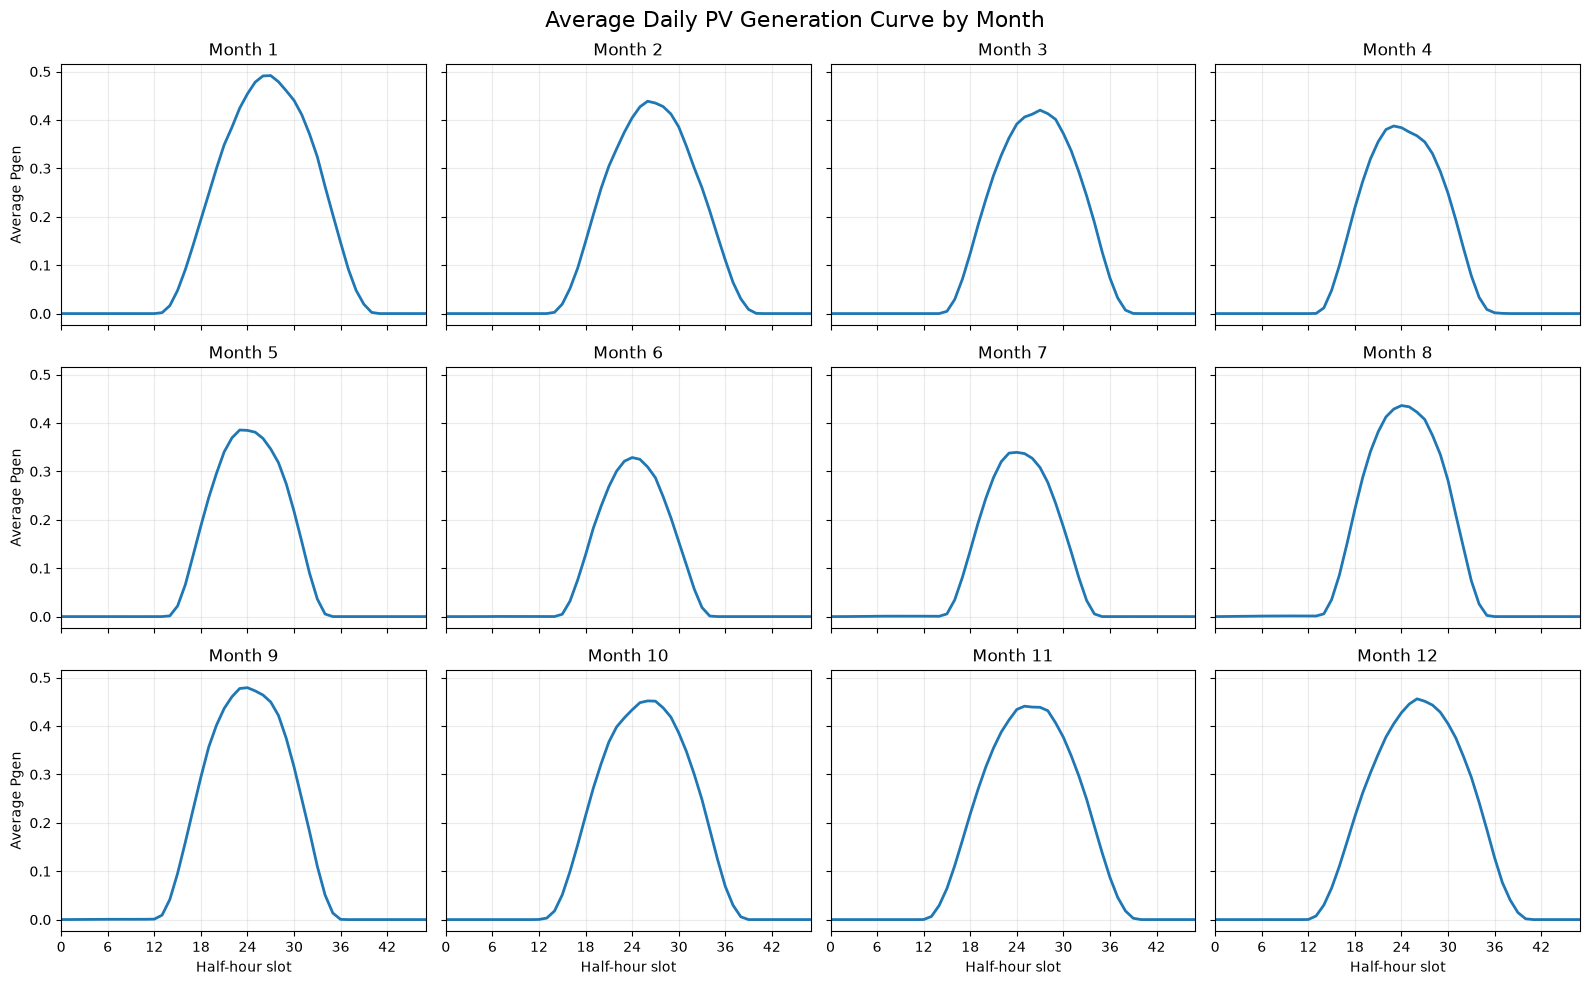

In [25]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for month in range(1, 13):
    ax = axes[month - 1]
    month_data = avg_profile_2[avg_profile_2["month"] == month].sort_values("half_hour_slot")
    ax.plot(month_data["half_hour_slot"], month_data["Pgen"], color="tab:blue", linewidth=2)
    ax.set_title(f"Month {month}")
    ax.set_xlim(0, 47)
    ax.set_xticks(np.arange(0, 48, 6))
    ax.grid(alpha=0.25)
    if month in [1, 5, 9]:
        ax.set_ylabel("Average Pgen")
    if month in [9, 10, 11, 12]:
        ax.set_xlabel("Half-hour slot")

fig.suptitle("Average Daily PV Generation Curve by Month", fontsize=16)
fig.tight_layout()
plt.show()

For the unseen-datetime test set, we join each row to that customer's average profile in `avg_profile_1` (on customer, month and half-hour slot). For the two unseen-customer test sets, there is no customer-specific profile, so we join to `avg_profile_2` (on month and half-hour slot). In both cases the profile's `Pgen` becomes the prediction, `Pgen_Pred_avg`. `validate='many_to_one'` checks that each profile key has at most one match.

In [26]:
def predict_avg_profile(test_data, profile, keys):
    predictions = add_slots(test_data).merge(
        profile.rename(columns={"Pgen": "Pgen_Pred_avg"}),
        on=keys,
        how="left",
        validate="many_to_one",
    )
    return predictions


avg_predictions = {
    "Unseen datetimes": predict_avg_profile(
        datetime_test_data, avg_profile_1, ["Customer", "month", "half_hour_slot"]),
    "Unseen customers": predict_avg_profile(
        customer_test_data, avg_profile_2, ["month", "half_hour_slot"]),
    "Unseen customers + datetimes": predict_avg_profile(
        unseen_customer_datetime_test_data, avg_profile_2, ["month", "half_hour_slot"]),
}

average_metrics = evaluate(avg_predictions, "Pgen_Pred_avg")
show_metrics(average_metrics)

Test set,MAE,RMSE,Rows evaluated
Unseen datetimes,0.0519,0.1196,"2,358,136"
Unseen customers,0.0722,0.1639,"1,949,580"
Unseen customers + datetimes,0.0698,0.1542,"417,780"


## Previous Day Baseline

This baseline predicts each customer's generation from the same half-hour on the previous day, which measures how much generation varies from day to day. It uses historical observations rather than a trained model, so it looks values up in the full dataset rather than in the training set.

`source` is a Series of `Pgen` values indexed by `(Customer, datetime)`. For each test set, we build lookup keys with the same customer and a timestamp exactly 24 hours earlier, then use `source` to fetch that customer's `Pgen` for those keys. The results go in a `Pgen_Pred_prev-day` column. Rows with no previous-day value (the first day of the data) get `NaN`.

In [27]:
source = data.set_index(['Customer', 'datetime'])['Pgen']

prev_day_predictions = {}
for dataset_name, test_data in test_sets.items():
    predictions = test_data[["Customer", "datetime", "Pgen"]].copy()
    previous_keys = pd.MultiIndex.from_arrays([
        predictions["Customer"],
        predictions["datetime"] - pd.Timedelta(days=1),
    ])
    predictions["Pgen_Pred_prev-day"] = source.reindex(previous_keys).to_numpy()
    prev_day_predictions[dataset_name] = predictions

prev_day_metrics = evaluate(prev_day_predictions, "Pgen_Pred_prev-day")
show_metrics(prev_day_metrics)

Test set,MAE,RMSE,Rows evaluated
Unseen datetimes,0.0501,0.1367,"2,358,136"
Unseen customers,0.0570,0.1420,"1,947,420"
Unseen customers + datetimes,0.0523,0.1322,"417,780"


## Baseline Summary

In [28]:
baseline_summary = pd.concat([
    average_metrics.assign(Method="Average baseline"),
    prev_day_metrics.assign(Method="Previous-day baseline"),
], ignore_index=True)[["Method", "Test set", "MAE", "RMSE", "Rows evaluated"]]

show_metrics(baseline_summary)

Method,Test set,MAE,RMSE,Rows evaluated
Average baseline,Unseen datetimes,0.0519,0.1196,"2,358,136"
Average baseline,Unseen customers,0.0722,0.1639,"1,949,580"
Average baseline,Unseen customers + datetimes,0.0698,0.1542,"417,780"
Previous-day baseline,Unseen datetimes,0.0501,0.1367,"2,358,136"
Previous-day baseline,Unseen customers,0.0570,0.1420,"1,947,420"
Previous-day baseline,Unseen customers + datetimes,0.0523,0.1322,"417,780"


# Part 3: PCA and Linear Regression

Can a set of uncorrelated weather components predict `Pgen` better than irradiance alone? We first fit a linear regression on irradiance alone. Then we use PCA to turn temperature, wind, irradiance, cloud cover and sun position into uncorrelated components, and regress `Pgen` on those components. This is called principal component regression (PCR). All of these variables affect how much solar radiation reaches the panels.

## Irradiance Linear Regression

We fit `Pgen = a × shortwave_radiation + b` in two ways: once globally across all training customers, and once separately for each customer.

In [29]:
# Fit the global model
global_a, global_b = np.polyfit(
    train_data['shortwave_radiation'].to_numpy(),
    train_data['Pgen'].to_numpy(),
    1)

# Fit the per-customer models
customer_coefficients = {}
for customer, group in train_data.groupby('Customer'):
    customer_coefficients[customer] = np.polyfit(
        group['shortwave_radiation'].to_numpy(),
        group['Pgen'].to_numpy(),
        1)

For each row, the prediction uses that customer's fitted `(a, b)` coefficients if they exist, and the global `(global_a, global_b)` pair otherwise, which covers unseen customers. Negative predictions are clipped to zero. The predictions go in `Pgen_Pred_lin-regress`.

In [30]:
def predict_irradiance(test_data):
    predictions = test_data[["Customer", "datetime", "Pgen", "shortwave_radiation"]].copy()
    coefficients = [
        customer_coefficients.get(customer, (global_a, global_b))
        for customer in predictions["Customer"]
    ]
    a, b = np.array(coefficients).T  # Transpose to separate arrays
    predictions["Pgen_Pred_lin-regress"] = np.maximum(
        a * predictions['shortwave_radiation'].to_numpy() + b, 0)
    return predictions


lin_reg_predictions = {name: predict_irradiance(df) for name, df in test_sets.items()}
lin_reg_metrics = evaluate(lin_reg_predictions, "Pgen_Pred_lin-regress")
show_metrics(lin_reg_metrics)

Test set,MAE,RMSE,Rows evaluated
Unseen datetimes,0.0544,0.1147,"2,358,136"
Unseen customers,0.0751,0.1616,"1,949,580"
Unseen customers + datetimes,0.0703,0.1478,"417,780"


## PCA Data Preparation

PCA and PCR are fitted on **daylight rows only** (`solar_zenith < 90`). At night generation is zero, and the night rows would otherwise dominate the components. To keep the metrics comparable with the baselines, which are scored on every row, PCR predicts zero at night and is scored on the same full test sets.

The model inputs are listed explicitly: the weather and sun-position features plus `Generator Capacity`. The identifiers, the target, and the raw `solar_zenith` (replaced by its cosine) are excluded.

In [31]:
feature_cols = [
    'Generator Capacity',
    'temperature_2m', 'wind_speed_10m', 'shortwave_radiation', 'cloud_cover',
    'direct_normal_irradiance', 'diffuse_radiation', 'sunshine_duration',
    'cos_solar_zenith', 'azimuth_sin', 'azimuth_cos',
    'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
]
# PCA uses weather and sun-position features only
pca_cols = [c for c in feature_cols if c != 'Generator Capacity']


def daylight_rows(df):
    # Daylight rows with complete features
    mask = (df['solar_zenith'] < 90) & df[feature_cols].notna().all(axis=1)
    return df.loc[mask, ['Customer', 'datetime', 'Pgen'] + feature_cols].copy()


train_day = daylight_rows(train_data)
print(f"Daylight training rows: {len(train_day):,} of {len(train_data):,}")

Daylight training rows: 5,487,416 of 11,004,296


### Data Normalization

The scaler is fitted on the daylight training rows only and applied to the test sets later. It scales copies, so the shared splits from Part 1 stay unchanged.

In [32]:
scaler = StandardScaler()
train_day[feature_cols] = scaler.fit_transform(train_day[feature_cols])
display(train_day.head())

,Customer,datetime,Pgen,Generator Capacity,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
6992991,134,2010-07-01 07:30:00,0.000,-0.174120,-2.841193,-0.696111,-1.396983,0.46376,-1.399517,-1.426872,-1.959419,-1.61709,1.062731,0.215463,1.401234,1.034745,0.219771,-1.544473
12779871,244,2010-07-01 07:30:00,0.000,0.316866,-2.841193,-0.696111,-1.396983,0.46376,-1.399517,-1.426872,-1.959419,-1.61709,1.062731,0.215463,1.401234,1.034745,0.219771,-1.544473
7203423,138,2010-07-01 07:30:00,0.013,2.205273,-2.841193,-0.696111,-1.396983,0.46376,-1.399517,-1.426872,-1.959419,-1.61709,1.062731,0.215463,1.401234,1.034745,0.219771,-1.544473
3363039,65,2010-07-01 07:30:00,0.020,-0.155236,-2.841193,-0.696111,-1.396983,0.46376,-1.399517,-1.426872,-1.959419,-1.61709,1.062731,0.215463,1.401234,1.034745,0.219771,-1.544473
4888671,94,2010-07-01 07:30:00,0.000,-0.608454,-2.841193,-0.696111,-1.396983,0.46376,-1.399517,-1.426872,-1.959419,-1.61709,1.062731,0.215463,1.401234,1.034745,0.219771,-1.544473


### Data Exploration: Correlation Heatmap

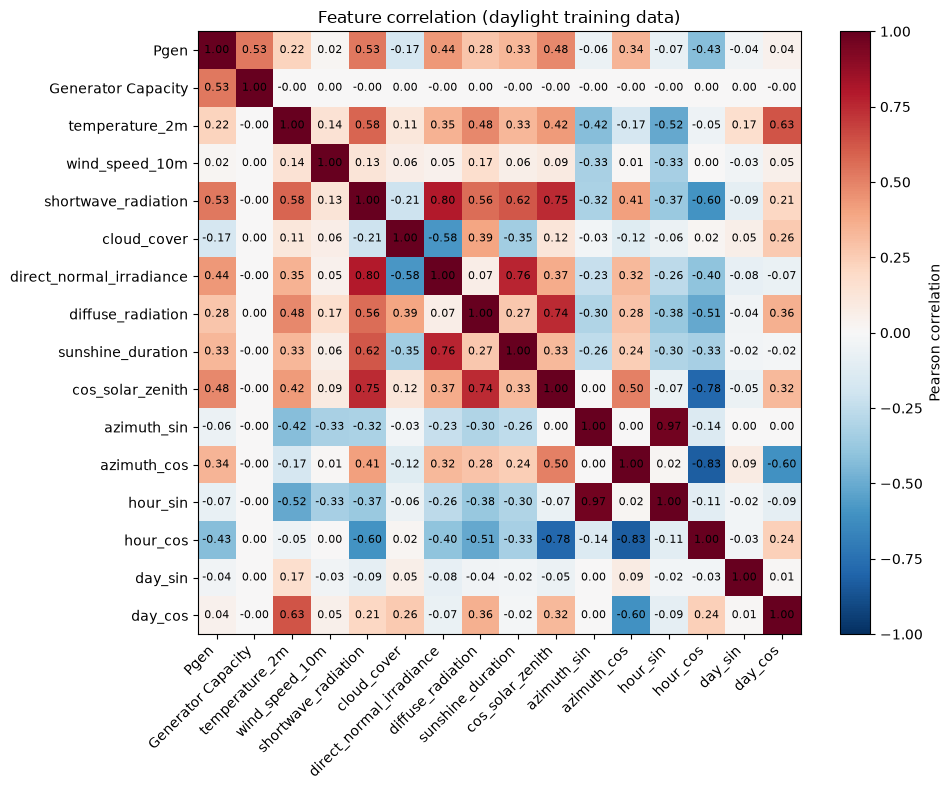

In [33]:
corr = train_day[['Pgen'] + feature_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Feature correlation (daylight training data)')
plt.tight_layout()
plt.show()

`Pgen` is most strongly related to `shortwave_radiation` (0.53), `Generator Capacity` (0.53), `cos_solar_zenith` (0.48) and `direct_normal_irradiance` (0.44). It is negatively related to `hour_cos` (-0.43), which is lowest at midday. `cloud_cover` has a weak negative relationship with generation (-0.17) and a stronger one with direct irradiance (-0.58), as expected.

Many features are highly correlated with each other:

- `shortwave_radiation` correlates at 0.56–0.80 with the other radiation variables and `cos_solar_zenith`. Direct and diffuse radiation are nearly unrelated to each other (0.07), but each is strongly linked to one of the others: `direct_normal_irradiance` with `sunshine_duration` (0.76), and `diffuse_radiation` with `cos_solar_zenith` (0.74).
- `hour_sin` is almost identical to `azimuth_sin` (0.97), and `hour_cos` closely tracks both `cos_solar_zenith` (-0.78) and `azimuth_cos` (-0.83). Clock time and sun position describe the same daily cycle.
- `day_cos` captures the seasons. It is linked to temperature (0.63) and to `azimuth_cos` (-0.60), because the sun's direction changes over the year.

Because these features overlap so much, PCA should be able to combine them into a smaller set of uncorrelated components. `Generator Capacity` is unrelated to every weather feature, so it is left out of PCA and added back to the regression directly. `day_sin` shows little relationship with anything, and `wind_speed_10m` is only moderately related to the daily cycle (-0.33 with `hour_sin` and `azimuth_sin`).

## Fit PCA on the Training Data

Component,Explained variance,Cumulative
PC1,0.326,0.326
PC2,0.195,0.521
PC3,0.150,0.671
PC4,0.111,0.782
PC5,0.076,0.858
PC6,0.058,0.916
PC7,0.033,0.948
PC8,0.021,0.970
PC9,0.012,0.982
PC10,0.007,0.989


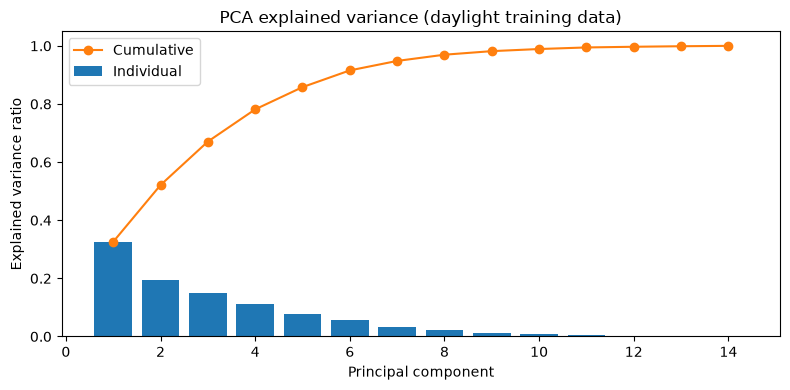

In [34]:
pca = PCA()
pca.fit(train_day[pca_cols])

explained = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(pca.n_components_)],
    'Explained variance': pca.explained_variance_ratio_,
    'Cumulative': np.cumsum(pca.explained_variance_ratio_)
})
display(explained.style.format({'Explained variance': '{:.3f}', 'Cumulative': '{:.3f}'}).hide(axis='index'))

# Scree plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, pca.n_components_ + 1), pca.explained_variance_ratio_, label='Individual')
ax.plot(range(1, pca.n_components_ + 1), np.cumsum(pca.explained_variance_ratio_), 'o-', color='C1', label='Cumulative')
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA explained variance (daylight training data)')
ax.legend()
plt.tight_layout()
plt.show()

We keep the smallest number of components that retains about 95% of the variance. This turns out to be 7 components, which halves the number of inputs and removes the multicollinearity between the original features.

In [35]:
variance_target = 0.95
n_components = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), variance_target) + 1)
print(f"Components kept: {n_components} "
      f"({np.cumsum(pca.explained_variance_ratio_)[n_components - 1]:.1%} of variance)")

Components kept: 8 (97.0% of variance)


## Principal Component Regression

The global model uses the first `n_components` principal components plus `Generator Capacity`. The per-customer models use the components only, because capacity is constant within a customer.

In [36]:
def get_pcs(df):
    return pca.transform(df[pca_cols])[:, :n_components]


def get_pc_features(df):
    # First k principal components plus Generator Capacity
    return np.column_stack([get_pcs(df), df['Generator Capacity'].to_numpy()])


# Fit the global model on all training customers
global_model = LinearRegression().fit(get_pc_features(train_day), train_day['Pgen'])

# Fit the per-customer models
customer_models = {}
for customer, group in train_day.groupby('Customer'):
    customer_models[customer] = LinearRegression().fit(get_pcs(group), group['Pgen'])

For each customer, the prediction uses that customer's own model if one was trained, and the global model otherwise (which covers unseen customers). Daylight rows are scaled with the training scaler before prediction, night rows are predicted as zero, and negative predictions are clipped to zero.

In [37]:
def predict_pcr(test_data):
    predictions = test_data[["Customer", "datetime", "Pgen"]].copy()

    # Sun below the horizon -> no generation
    predictions['Pgen_Pred_pcr'] = np.where(test_data['solar_zenith'] >= 90, 0.0, np.nan)

    day = daylight_rows(test_data)
    day[feature_cols] = scaler.transform(day[feature_cols])
    day_pred = pd.Series(global_model.predict(get_pc_features(day)), index=day.index)

    for customer, idx in day.groupby('Customer').groups.items():
        if customer in customer_models:
            day_pred.loc[idx] = customer_models[customer].predict(get_pcs(day.loc[idx]))

    predictions.loc[day.index, 'Pgen_Pred_pcr'] = day_pred.clip(lower=0)
    return predictions


pcr_predictions = {name: predict_pcr(df) for name, df in test_sets.items()}
pcr_metrics = evaluate(pcr_predictions, "Pgen_Pred_pcr")
show_metrics(pcr_metrics)

Test set,MAE,RMSE,Rows evaluated
Unseen datetimes,0.0444,0.1014,"2,358,136"
Unseen customers,0.0589,0.1219,"1,949,580"
Unseen customers + datetimes,0.0611,0.1330,"417,780"


## Summary: All Methods

In [28]:
summary = pd.concat([
    average_metrics.assign(Method="Average baseline"),
    prev_day_metrics.assign(Method="Previous-day baseline"),
    lin_reg_metrics.assign(Method="Irradiance linear regression"),
    pcr_metrics.assign(Method="PCA regression (PCR)"),
], ignore_index=True)[["Method", "Test set", "MAE", "RMSE", "Rows evaluated"]]

show_metrics(summary)

Method,Test set,MAE,RMSE,Rows evaluated
Average baseline,Unseen datetimes,0.0519,0.1196,"2,358,136"
Average baseline,Unseen customers,0.0722,0.1639,"1,949,580"
Average baseline,Unseen customers + datetimes,0.0698,0.1542,"417,780"
Previous-day baseline,Unseen datetimes,0.0501,0.1367,"2,358,136"
Previous-day baseline,Unseen customers,0.0570,0.1420,"1,947,420"
Previous-day baseline,Unseen customers + datetimes,0.0523,0.1322,"417,780"
Irradiance linear regression,Unseen datetimes,0.0545,0.1147,"2,357,882"
Irradiance linear regression,Unseen customers,0.0751,0.1616,"1,949,580"
Irradiance linear regression,Unseen customers + datetimes,0.0703,0.1479,"417,735"
PCA regression (PCR),Unseen datetimes,0.0445,0.1014,"2,357,374"


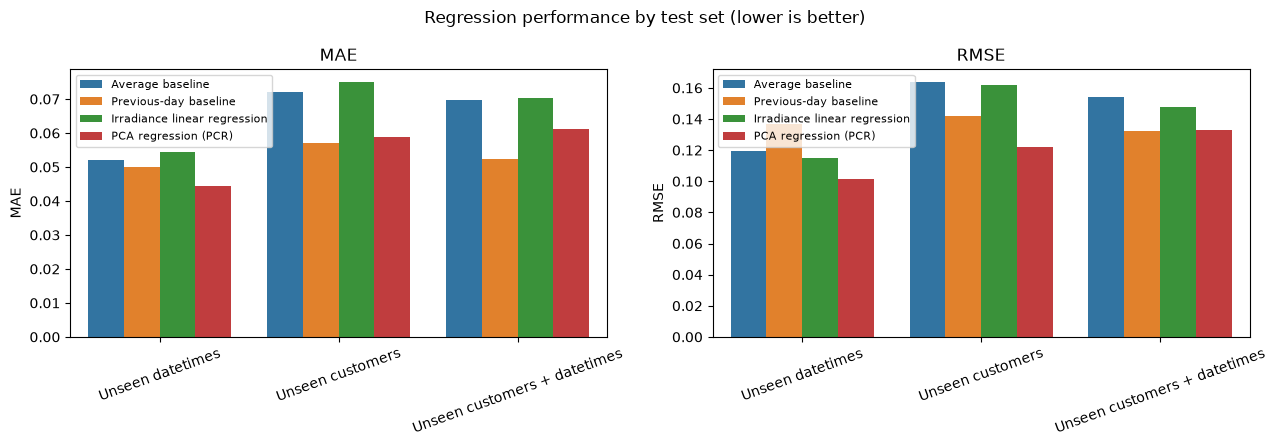

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)

for ax, metric in zip(axes, ["MAE", "RMSE"]):
    sns.barplot(data=summary, x="Test set", y=metric, hue="Method", ax=ax)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="", fontsize=8)

fig.suptitle("Regression performance by test set (lower is better)")
fig.tight_layout()
plt.show()

PCA regression (PCR) gives the lowest RMSE on two of the three test sets, and ties with the previous-day baseline on the third. Its MAE is only the lowest on unseen datetimes.

- **Unseen datetimes:** PCR does best on both measures (MAE 0.0445, RMSE 0.1014). The next best are the previous-day baseline on MAE (0.0501) and the irradiance regression on RMSE (0.1147).
- **Unseen customers:** the previous-day baseline has a slightly lower MAE than PCR (0.0570 vs 0.0589), but PCR has a clearly lower RMSE (0.1219 vs 0.1420).
- **Unseen customers + datetimes:** the previous-day baseline has a clearly lower MAE (0.0523 vs 0.0611), and the two have almost the same RMSE (0.1322 vs 0.1330).

The previous-day baseline beats the average curve on MAE in every test set. However, on unseen datetimes its RMSE is worse (0.1367 vs 0.1196). It is usually close, but when the weather changes from one day to the next it can be far off, and RMSE penalises those large errors heavily. It also has an advantage the other methods lack: it uses the customer's own generation from the day before. This means it already reflects that customer's system size and orientation, even in the "unseen customers" test sets.

The irradiance-only regression is no better than the average baseline. Its RMSE is slightly lower but its MAE is slightly higher in every test set. Irradiance alone is not enough to predict PV generation. Adding sun position, time and season features, and combining them through PCA, gives a clear improvement, especially on RMSE.